# PSF ellipticity per CCD in Az/El against RubinTV, and sonic anemometers EFD against ConsDB (v1)

**Author:** Aaron Roodman (with Claude)  
**Date Created:** 2026-11-04  
**Last Modified:** 2026-11-04  
**Status:** In Progress  
**Keywords:** PSF ellipticity, whiskers, Az/El, OCS, ConsDB, sonic anemometer

## Description

The Consolidated Database (ConsDB) holds one PSF second-moment tensor per CCD
(`ccdvisit1_quicklook.psf_ixx/iyy/ixy`) in the detector pixel frame. This notebook rotates
them to the Azimuth/Elevation frame with `rubinwork.psf_shape` and checks the result
against the RubinTV `psf_shape_azel` plots for four visits from `day_obs` 20261027, chosen
for large ellipticity and rotator angles from -45.7 to +50.9 deg.

1. Whisker, e1 and e2 maps per CCD in Az/El (+x = increasing azimuth, +y = increasing
   elevation), beside the RubinTV PNG.
2. The Az/El directions from a boresight WCS, to test the rotation independently, and the
   relation of Az/El to the AOS Observatory Coordinate System (OCS).
3. The per-visit statistics the value-added `psf_shape` group stores.
4. Sonic-anemometer values from the raw EFD (value-added `sonic` group) against the
   ConsDB transformed EFD.

**Output:** one PDF in the study run directory.

**Based on:** `lsst.summit.extras.plotting.psfPlotting.makeAzElPlot`; SITCOMTN-003 for the
OCS and CCS.

## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-11-04 | Aaron Roodman | Initial version |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Helper Functions](#functions)
4. [Data Access](#data)
5. [Whiskers against RubinTV](#whiskers)
6. [Az/El from the WCS, and the OCS](#wcs)
7. [Per-visit statistics](#stats)
8. [Sonic anemometers: EFD against ConsDB](#sonic)
9. [Summary](#summary)

<a id='params'></a>
## Parameters

In [1]:
from rubinwork.common import study_run

DAY_OBS = 20261027
SEQ_NUMS = [109, 111, 119, 131]
RUBINTV_PNG = 'notes/lsstcam_psf_shape_azel_2026-10-27_{seq:06d}.png'
EMBARGO_REPO = '/repo/embargo'
RAW_COLLECTION = 'LSSTCam/raw/all'
WCS_DETECTOR = 94                       # a central science CCD for the WCS test
QUIVER_SCALE = 1.5                      # quiver length per unit |e| [1/(axes width)]
# Scratch value-added database holding `sonic` and `psf_shape` for two test nights, made by
#   python -m rubinwork.products.value_added.builders.build_efd_db \
#       --day-obs 20261027,20260410 --groups sonic,psf_shape --db /tmp/ell/db/t.duckdb
TEST_DB = '/tmp/ell/db/t.duckdb'

run = study_run('value_added/psf_shape_frame', 'azel_vs_rubintv')
PDF_PATH = run.path / 'psf_shape_frame.pdf'
print(run.path)

/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/value_added/psf_shape_frame/20261104_azel_vs_rubintv


<a id='setup'></a>
## Setup & Imports

In [2]:
import asyncio

import duckdb
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.backends.backend_pdf import PdfPages

import astropy.units as u
from astropy.coordinates import AltAz, EarthLocation, SkyCoord
from astropy.time import Time

import lsst.geom as geom
from lsst.afw.cameraGeom import FOCAL_PLANE, PIXELS
from lsst.daf.butler import Butler
from lsst.obs.base import createInitialSkyWcsFromBoresight
from lsst.obs.lsst import LsstCam

from rubinwork import psf_shape
from rubinwork.common.consdb_efd import _query_cols
from rubinwork.common.telemetry_clients import make_consdb_client
from rubinwork.common.utils import repo_root

ROOT = repo_root()
cdb = make_consdb_client()
cam = LsstCam.getCamera()
POS = psf_shape.detector_field_angles()

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.


        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


<a id='functions'></a>
## Helper Functions

In [3]:
def whisker_panel(ax, x, y, e1, e2, title):
    """Headless whiskers of length |e| at angle atan2(e2, e1)/2, as RubinTV draws them."""
    e = np.hypot(e1, e2)
    a = 0.5 * np.arctan2(e2, e1)
    q = ax.quiver(x, y, e * np.cos(a), e * np.sin(a), headlength=0, headaxislength=0,
                  pivot='middle', scale=QUIVER_SCALE)
    ax.quiverkey(q, X=0.12, Y=0.94, U=0.1, label='|e| = 0.1', labelpos='S')
    ax.set_title(title, fontsize=9)
    ax.set_xlim(-2.2, 2.2)
    ax.set_ylim(-2.2, 2.2)
    ax.set_aspect('equal')
    ax.set_xlabel(r'$\Delta$ Azimuth [deg]')
    ax.set_ylabel(r'$\Delta$ Elevation [deg]')


def scatter_panel(ax, x, y, v, label):
    sc = ax.scatter(x, y, c=v, s=60, marker='s', cmap='bwr', vmin=-0.2, vmax=0.2)
    plt.colorbar(sc, ax=ax, label=f'{label} (dimensionless, Az/El frame)', shrink=0.8)
    ax.set_xlim(-2.2, 2.2)
    ax.set_ylim(-2.2, 2.2)
    ax.set_aspect('equal')
    ax.set_xlabel(r'$\Delta$ Azimuth [deg]')
    ax.set_title(label, fontsize=9)

<a id='data'></a>
## Data Access

Per-CCD moments and the rotator angle for the four visits.

In [4]:
vids = [DAY_OBS * 100000 + s for s in SEQ_NUMS]
vlist = ', '.join(str(v) for v in vids)
ccd = cdb.query(
    f'SELECT c.visit_id, c.detector, q.psf_ixx, q.psf_iyy, q.psf_ixy, q.n_psf_star '
    f'FROM cdb_lsstcam.ccdvisit1 c JOIN cdb_lsstcam.ccdvisit1_quicklook q '
    f'ON q.ccdvisit_id = c.ccdvisit_id WHERE c.visit_id IN ({vlist})').to_pandas()
for c in ('psf_ixx', 'psf_iyy', 'psf_ixy'):
    ccd[c] = pd.to_numeric(ccd[c], errors='coerce')
ccd = ccd[ccd.detector.isin(POS.keys())].dropna(subset=['psf_ixx'])
meta = cdb.query(
    f'SELECT v.visit_id, v.seq_num, v.band, v.azimuth, v.altitude, '
    f'q.physical_rotator_angle FROM cdb_lsstcam.visit1 v '
    f'JOIN cdb_lsstcam.visit1_quicklook q ON q.visit_id = v.visit_id '
    f'WHERE v.visit_id IN ({vlist})').to_pandas().set_index('visit_id').loc[vids]
for c in ('azimuth', 'altitude', 'physical_rotator_angle'):
    meta[c] = pd.to_numeric(meta[c])
print(ccd.groupby('visit_id').size().rename('n_ccd (CCDs with moments)'))
meta

visit_id
2026102700109    188
2026102700111    187
2026102700119    188
2026102700131    188
Name: n_ccd (CCDs with moments), dtype: int64


,seq_num,band,azimuth,altitude,physical_rotator_angle
visit_id,,,,,
2026102700109,109,g,132.573799,66.689289,-45.658978
2026102700111,111,g,71.350555,37.054121,-40.985400
2026102700119,119,i,135.188376,68.411287,-40.481840
2026102700131,131,i,115.770476,41.063958,50.912467


<a id='whiskers'></a>
## Whiskers against RubinTV

Each row: the ConsDB per-CCD whiskers, e1 and e2 in Az/El, then the RubinTV plot. RubinTV
uses rotTelPos from the `visitInfo`; ConsDB `physical_rotator_angle` differs from it by
0.2 to 0.4 deg on these visits, which rotates e1/e2 by twice that, at most 0.8 deg.

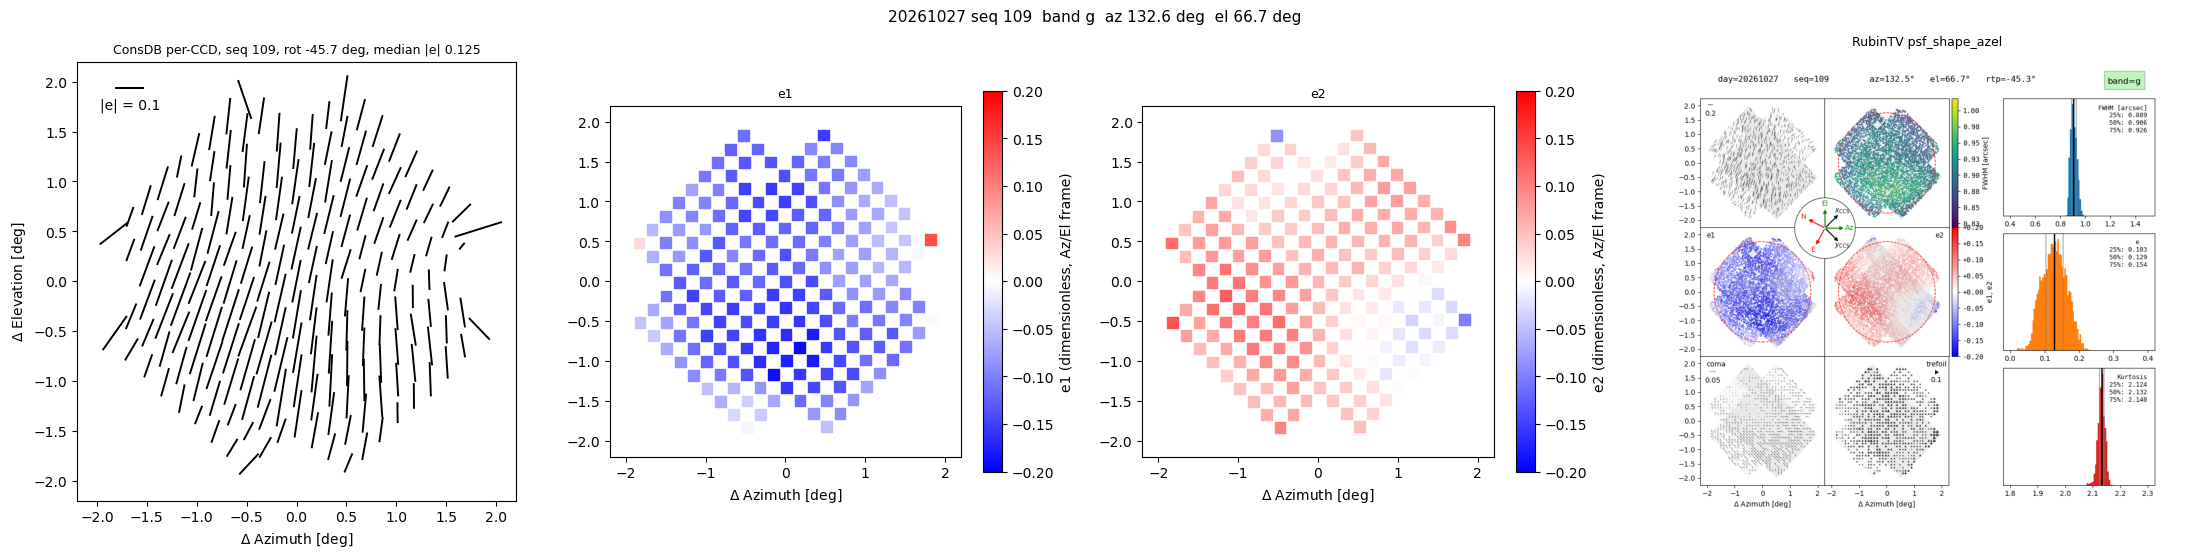

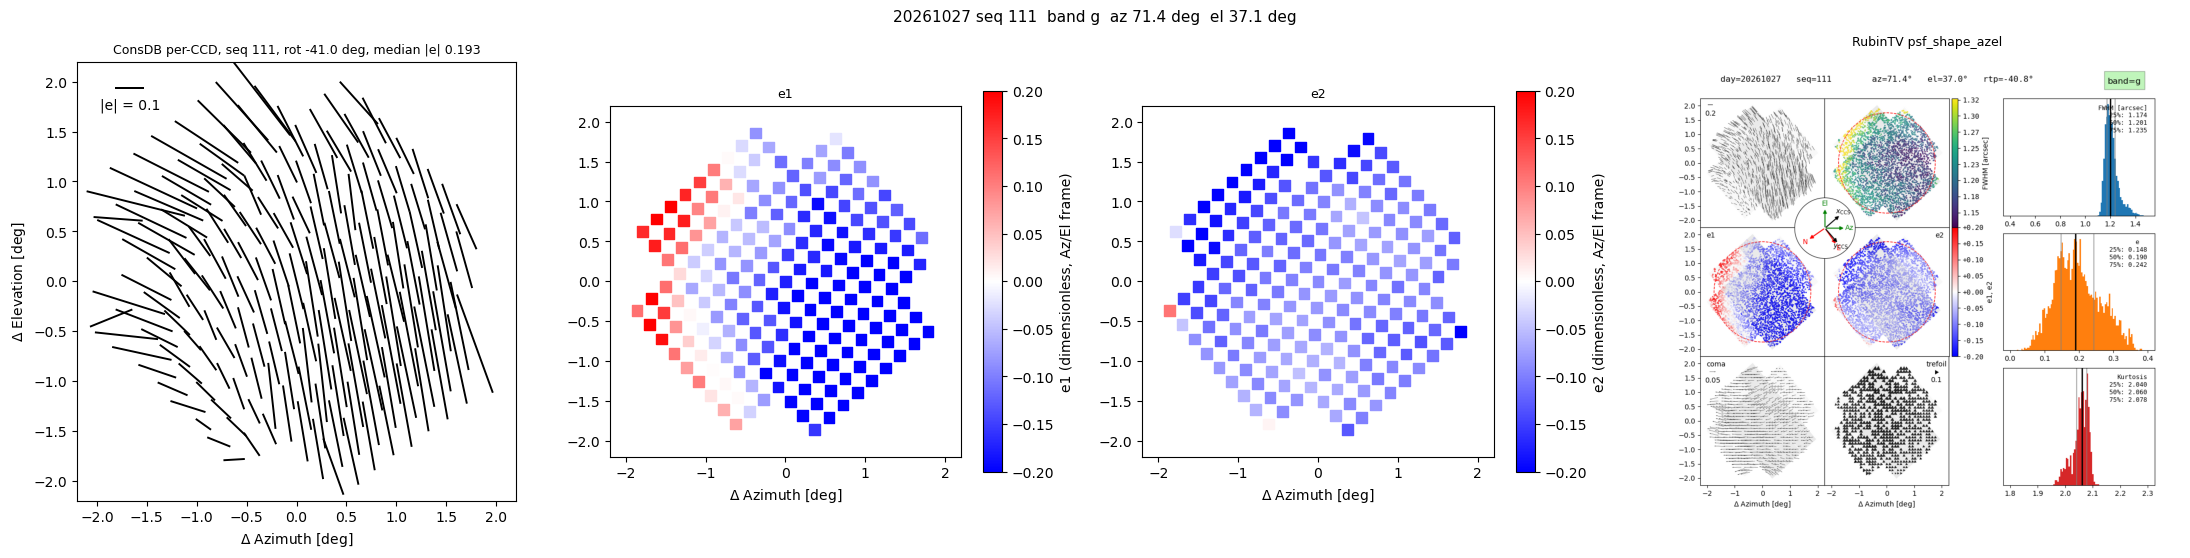

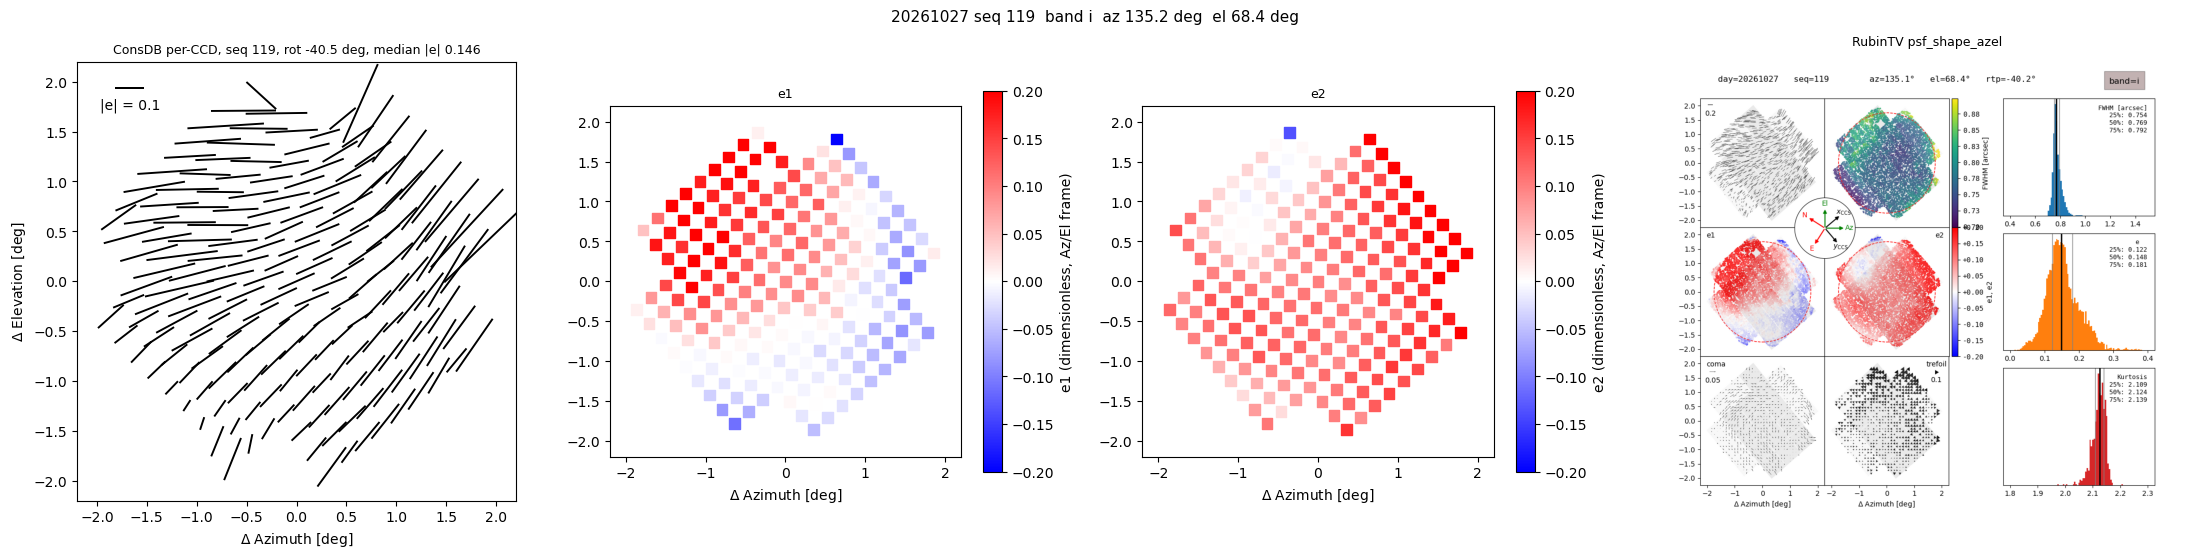

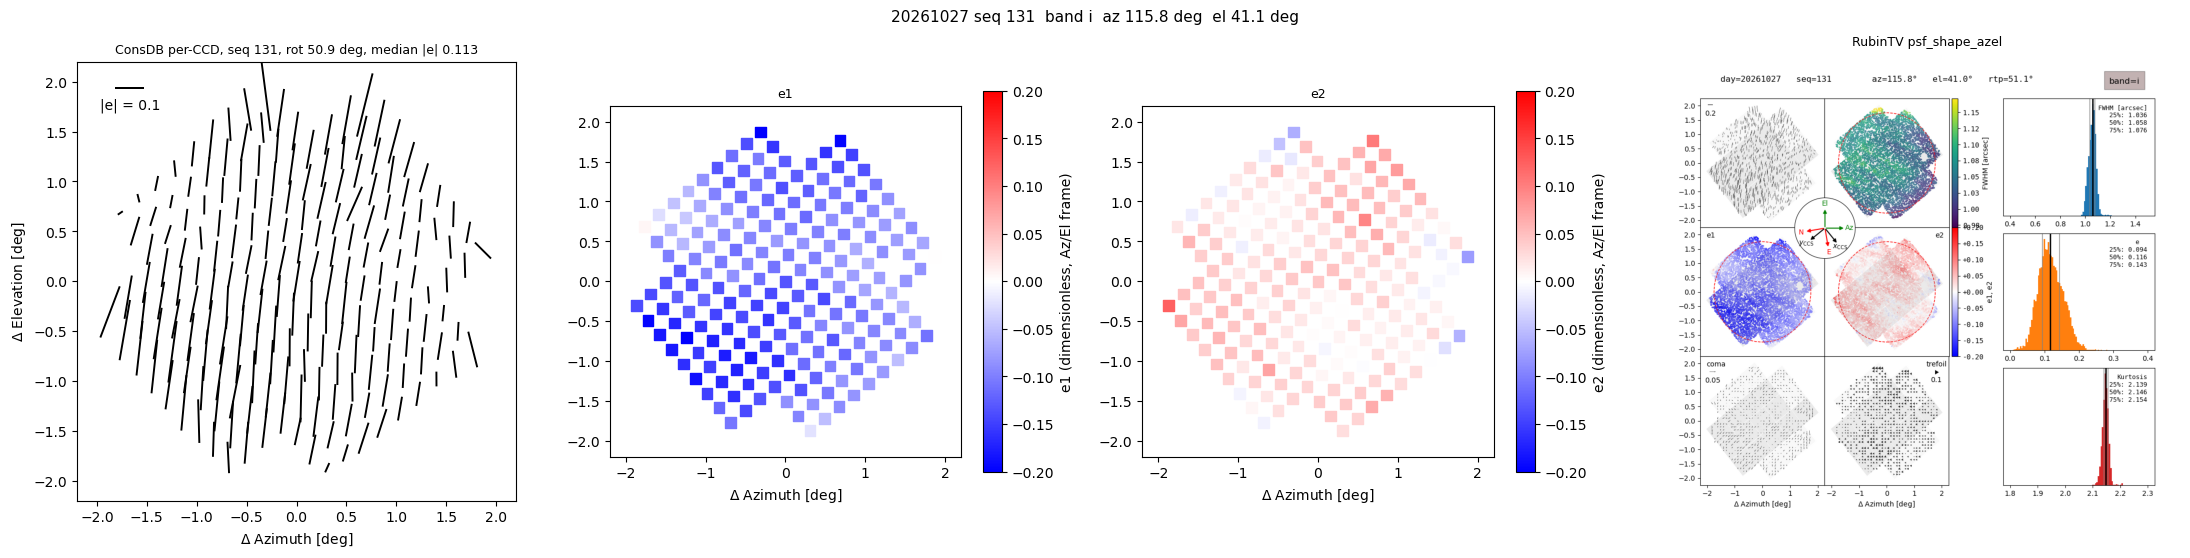

In [5]:
pdf = PdfPages(PDF_PATH)
summary_lines = []
shapes = {}
for vid in vids:
    g = ccd[ccd.visit_id == vid]
    m = meta.loc[vid]
    rot = float(m.physical_rotator_angle)
    e1, e2 = psf_shape.moments_to_azel(g.psf_ixx.to_numpy(), g.psf_iyy.to_numpy(),
                                       g.psf_ixy.to_numpy(), rot)
    xy = np.array([POS[int(d)] for d in g.detector])
    p = (psf_shape.azel_rotation(rot) @ xy.T).T
    shapes[vid] = (p, e1, e2)
    fig, axs = plt.subplots(1, 4, figsize=(22, 5.5),
                            gridspec_kw={'width_ratios': [1, 1, 1, 1.15]})
    whisker_panel(axs[0], p[:, 0], p[:, 1], e1, e2,
                  f'ConsDB per-CCD, seq {m.seq_num}, rot {rot:.1f} deg, '
                  f'median |e| {np.median(np.hypot(e1, e2)):.3f}')
    scatter_panel(axs[1], p[:, 0], p[:, 1], e1, 'e1')
    scatter_panel(axs[2], p[:, 0], p[:, 1], e2, 'e2')
    axs[3].imshow(mpimg.imread(ROOT / RUBINTV_PNG.format(seq=int(m.seq_num))))
    axs[3].axis('off')
    axs[3].set_title('RubinTV psf_shape_azel', fontsize=9)
    fig.suptitle(f'{DAY_OBS} seq {m.seq_num}  band {m.band}  az {m.azimuth:.1f} deg  '
                 f'el {m.altitude:.1f} deg', fontsize=11)
    fig.tight_layout()
    pdf.savefig(fig)
    plt.show()

<a id='wcs'></a>
## Az/El from the WCS, and the OCS

An independent test of the rotation: build a boresight WCS for one central CCD from the
raw `visitInfo`, step 10 mm along each DVCS focal-plane axis, and transform the sky
positions to Az/El. The columns of the resulting Jacobian are the (dAz cos El, dEl)
directions of DVCS +x and +y. They should equal `psf_shape.azel_rotation(rotTelPos)`.

The same Jacobian expressed in the AOS OCS axes (CCS = DVCS transposed; OCS = CCS rotated
by rotTelPos, SITCOMTN-003) tells us how OCS relates to Az/El.

In [6]:
butler = Butler(EMBARGO_REPO, instrument='LSSTCam', collections=[RAW_COLLECTION])
loc = EarthLocation(lat=-30.244639 * u.deg, lon=-70.749417 * u.deg, height=2663 * u.m)
T = np.array([[0, 1], [1, 0]])
rows = []
for vid, m in meta.iterrows():
    ref = list(butler.query_datasets(
        'raw', where=f'exposure.day_obs={DAY_OBS} and exposure.seq_num={m.seq_num} '
                     f'and detector={WCS_DETECTOR}', limit=1))[0]
    vi = butler.get(ref.makeComponentRef('visitInfo'))
    rtp = (vi.boresightParAngle - vi.boresightRotAngle
           - (np.pi / 2 * geom.radians)).wrapNear(0 * geom.radians).asRadians()
    det = cam[WCS_DETECTOR]
    wcs = createInitialSkyWcsFromBoresight(vi.boresightRaDec, vi.boresightRotAngle, det)
    frame = AltAz(obstime=Time(vi.date.toPython(), scale='tai'), location=loc)
    tr = det.getTransform(PIXELS, FOCAL_PLANE)
    c0 = det.getCenter(FOCAL_PLANE)
    aa = []
    for dx, dy in [(0, 0), (10, 0), (0, 10)]:
        sp = wcs.pixelToSky(tr.applyInverse(geom.Point2D(c0.getX() + dx, c0.getY() + dy)))
        s = SkyCoord(sp.getRa().asDegrees() * u.deg,
                     sp.getDec().asDegrees() * u.deg).transform_to(frame)
        aa.append((s.az.deg, s.alt.deg))
    (a0, e0), (ax_, ex), (ay, ey) = aa
    ce = np.cos(np.deg2rad(e0))
    J = np.array([[(ax_ - a0) * ce, (ay - a0) * ce], [ex - e0, ey - e0]])
    J /= np.linalg.norm(J[:, 0])
    R = psf_shape.azel_rotation(np.rad2deg(rtp))
    th = rtp
    Rocs = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    Jocs = J @ T @ np.linalg.inv(Rocs)
    rows.append({'seq_num': m.seq_num, 'rotTelPos_deg': np.rad2deg(rtp),
                 'physical_rotator_angle_deg': m.physical_rotator_angle,
                 'max |WCS - azel_rotation|': np.abs(J - R).max(),
                 'OCS +x -> (dAz, dEl)': np.round(Jocs[:, 0], 3),
                 'OCS +y -> (dAz, dEl)': np.round(Jocs[:, 1], 3)})
wcs_tab = pd.DataFrame(rows)
wcs_tab

INFO:botocore.credentials:Found credentials in shared credentials file: /sdf/home/r/roodman/.lsst/aws-credentials.ini


,seq_num,rotTelPos_deg,physical_rotator_angle_deg,max |WCS - azel_rotation|,"OCS +x -> (dAz, dEl)","OCS +y -> (dAz, dEl)"
0,109,-45.329503,-45.658978,0.003487,"[1.0, 0.005]","[0.004, -1.0]"
1,111,-40.792232,-40.985400,0.002034,"[1.0, 0.003]","[0.002, -1.0]"
2,119,-40.155055,-40.481840,0.003751,"[1.001, 0.005]","[0.004, -1.0]"
3,131,51.106441,50.912467,0.002865,"[1.0, 0.003]","[0.003, -1.0]"


The first test column is the largest element difference between the WCS Jacobian and
`azel_rotation` (dimensionless, unit vectors). The OCS columns show +x_OCS = +Az and
**+y_OCS = -El** at every rotator angle: the OCS is the Az/El frame mirrored in elevation,
so `e1_ocs = e1_azel` and `e2_ocs = -e2_azel`.

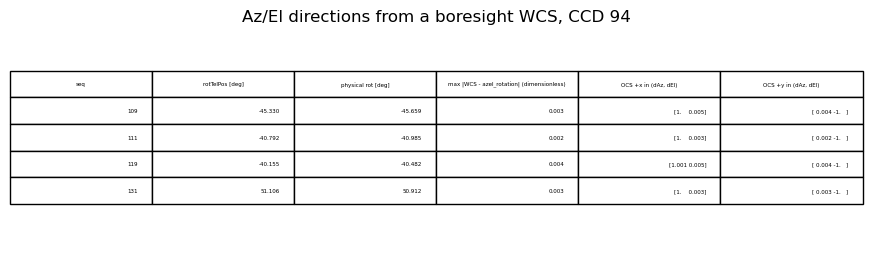

In [7]:
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.axis('off')
tab = wcs_tab.copy()
for c in ('rotTelPos_deg', 'physical_rotator_angle_deg', 'max |WCS - azel_rotation|'):
    tab[c] = tab[c].map(lambda v: f'{v:.3f}')
tab['OCS +x -> (dAz, dEl)'] = tab['OCS +x -> (dAz, dEl)'].map(str)
tab['OCS +y -> (dAz, dEl)'] = tab['OCS +y -> (dAz, dEl)'].map(str)
ax.table(cellText=tab.values, colLabels=['seq', 'rotTelPos [deg]', 'physical rot [deg]',
         'max |WCS - azel_rotation| (dimensionless)', 'OCS +x in (dAz, dEl)',
         'OCS +y in (dAz, dEl)'], loc='center').scale(1, 1.6)
ax.set_title('Az/El directions from a boresight WCS, CCD 94')
pdf.savefig(fig)
plt.show()

<a id='stats'></a>
## Per-visit statistics

`psf_shape.visit_summary` on the same four visits: distribution of |e|, e1, e2 over CCDs,
and the raw two-point functions at 2 and 6 CCD pitches (0.469 and 1.407 deg, each
+/- 0.117 deg).

In [8]:
stats = []
for vid in vids:
    p, e1, e2 = shapes[vid]
    xy = np.array([POS[int(d)] for d in ccd[ccd.visit_id == vid].detector])
    s = psf_shape.visit_summary(e1, e2, xy[:, 0], xy[:, 1])
    s['seq_num'] = int(meta.loc[vid].seq_num)
    stats.append(s)
stats = pd.DataFrame(stats).set_index('seq_num')
cols = ['n_ccd', 'e_p25', 'e_p50', 'e_p75', 'e1_mean', 'e2_mean',
        'xi_e1e1_r2', 'xi_e1e2_r2', 'xi_e2e2_r2', 'xi_e1e1_r6', 'xi_e1e2_r6', 'xi_e2e2_r6',
        'xi_npair_r2', 'xi_npair_r6']
stats[cols].round(4)

,n_ccd,e_p25,e_p50,e_p75,e1_mean,e2_mean,xi_e1e1_r2,xi_e1e2_r2,xi_e2e2_r2,xi_e1e1_r6,xi_e1e2_r6,xi_e2e2_r6,xi_npair_r2,xi_npair_r6
seq_num,,,,,,,,,,,,,,
109,188,0.0990,0.1246,0.1498,-0.1054,0.0485,0.0132,-0.0057,0.0034,0.0119,-0.0056,0.0023,908,1918
111,187,0.1475,0.1934,0.2427,-0.1049,-0.1110,0.0257,0.0108,0.0123,0.0160,0.0120,0.0116,904,1904
119,188,0.1194,0.1459,0.1775,0.0495,0.1073,0.0089,0.0031,0.0130,0.0040,0.0053,0.0112,908,1918
131,188,0.0909,0.1131,0.1412,-0.1110,0.0270,0.0131,-0.0032,0.0009,0.0122,-0.0030,0.0006,908,1918


RubinTV quotes the 25/50/75% points of |e| over stars. Its values, read off the PNGs, are
set beside the per-CCD ones below; the per-CCD moments average many stars, so their
spread is narrower but the median should be close.

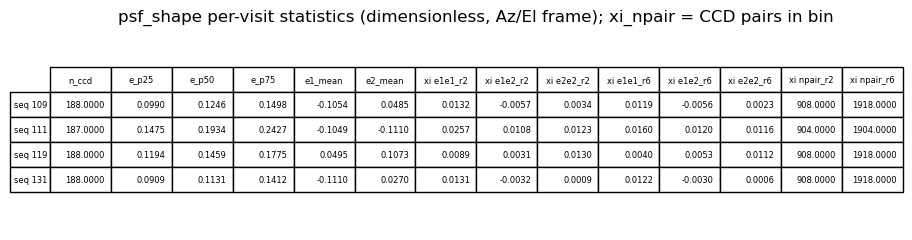

,RubinTV |e| p25/p50/p75 (stars),ConsDB |e| p25/p50/p75 (CCDs)
seq_num,,
109,"(0.103, 0.129, 0.154)","(0.099, 0.125, 0.150)"
111,"(0.148, 0.19, 0.242)","(0.148, 0.193, 0.243)"
119,"(0.122, 0.148, 0.181)","(0.119, 0.146, 0.177)"
131,"(0.094, 0.116, 0.143)","(0.091, 0.113, 0.141)"


In [9]:
rubintv_e = {109: (0.103, 0.129, 0.154), 111: (0.148, 0.190, 0.242),
             119: (0.122, 0.148, 0.181), 131: (0.094, 0.116, 0.143)}
cmp = pd.DataFrame({
    'RubinTV |e| p25/p50/p75 (stars)': [str(rubintv_e[s]) for s in stats.index],
    'ConsDB |e| p25/p50/p75 (CCDs)': [
        f'({r.e_p25:.3f}, {r.e_p50:.3f}, {r.e_p75:.3f})' for r in stats.itertuples()]},
    index=stats.index)
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.axis('off')
show = stats[cols].copy()
ax.table(cellText=[[f'{v:.4f}' if isinstance(v, float) else str(v) for v in r]
                   for r in show.values],
         colLabels=[c.replace('xi_', 'xi ') for c in cols],
         rowLabels=[f'seq {s}' for s in show.index], loc='center').scale(1, 1.5)
ax.set_title('psf_shape per-visit statistics (dimensionless, Az/El frame); '
             'xi_npair = CCD pairs in bin')
pdf.savefig(fig)
plt.show()
cmp

<a id='sonic'></a>
## Sonic anemometers: EFD against ConsDB

The value-added `sonic` group averages the raw 5 s `ESS.airTurbulence` samples over each
exposure. ConsDB's transformed EFD (`efd_lsstcam.exposure_efd`) holds the same sensors.
Two test nights: 20260410 (110 and 123-126 reporting) and 20261027 (123-126 only).

In [10]:
tdb = duckdb.connect(TEST_DB, read_only=True)
va = tdb.sql('SELECT * FROM visit_telemetry').df()
tdb.close()
sal = (110, 123, 124, 125, 126)
want = [f'mt_salindex{i}_wind_speed_{a}_mean' for i in sal for a in range(3)]
want += [f'mt_salindex{i}_wind_speed_stddev_{a}_mean' for i in sal for a in range(3)]
e = _query_cols(cdb, 'efd_lsstcam.exposure_efd', want, va.visit_id.tolist(), 'sonic')
e = e.drop_duplicates('exposure_id').rename(columns={'exposure_id': 'visit_id'})
both = va.merge(e, on='visit_id')
rows = []
for i in sal:
    for a in range(3):
        x = pd.to_numeric(both[f'mt_salindex{i}_wind_speed_{a}_mean'], errors='coerce')
        y = both[f'sonic{i}_mean_{a}_ms']
        g = x.notna() & y.notna()
        rows.append({'salIndex': i, 'axis': a, 'n visits': int(g.sum()),
                     'median |EFD - ConsDB| mean [m/s]':
                         np.median(np.abs(x[g] - y[g])) if g.any() else np.nan,
                     'n ConsDB only': int((x.notna() & y.isna()).sum()),
                     'n EFD only': int((x.isna() & y.notna()).sum())})
sonic_cmp = pd.DataFrame(rows)
sonic_cmp

,salIndex,axis,n visits,median |EFD - ConsDB| mean [m/s],n ConsDB only,n EFD only
0,110,0,723,0.0,0,107
1,110,1,723,0.0,0,107
2,110,2,723,0.0,0,107
3,123,0,1502,0.0,0,25
4,123,1,1502,0.0,0,25
5,123,2,1502,0.0,0,25
6,124,0,1502,0.0,0,25
7,124,1,1502,0.0,0,25
8,124,2,1502,0.0,0,25
9,125,0,1502,0.0,0,25


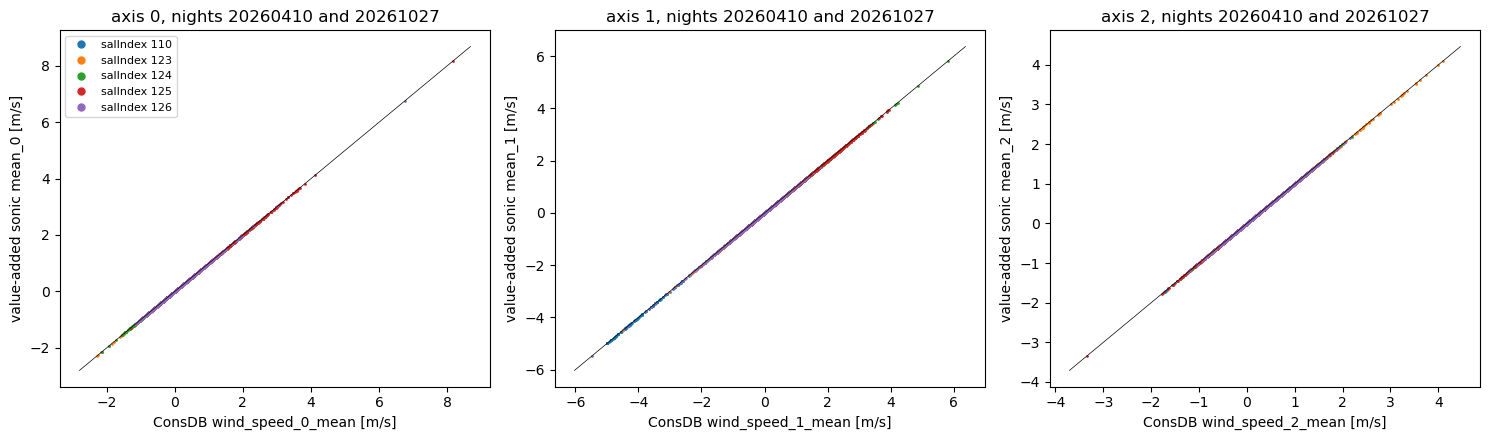

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for a, ax in enumerate(axs):
    for i in sal:
        x = pd.to_numeric(both[f'mt_salindex{i}_wind_speed_{a}_mean'], errors='coerce')
        y = both[f'sonic{i}_mean_{a}_ms']
        ax.plot(x, y, '.', ms=2, label=f'salIndex {i}')
    lim = ax.get_xlim()
    ax.plot(lim, lim, 'k-', lw=0.5)
    ax.set_xlabel(f'ConsDB wind_speed_{a}_mean [m/s]')
    ax.set_ylabel(f'value-added sonic mean_{a} [m/s]')
    ax.set_title(f'axis {a}, nights 20260410 and 20261027')
axs[0].legend(markerscale=5, fontsize=8)
fig.tight_layout()
pdf.savefig(fig)
plt.show()

The value-added RMS combines the within-sample spread (`speedStdDev`) and the spread of
the 5 s means over the exposure. ConsDB's `wind_speed_stddev_<a>_mean` is only the first
part, so the RMS should be at or above it.

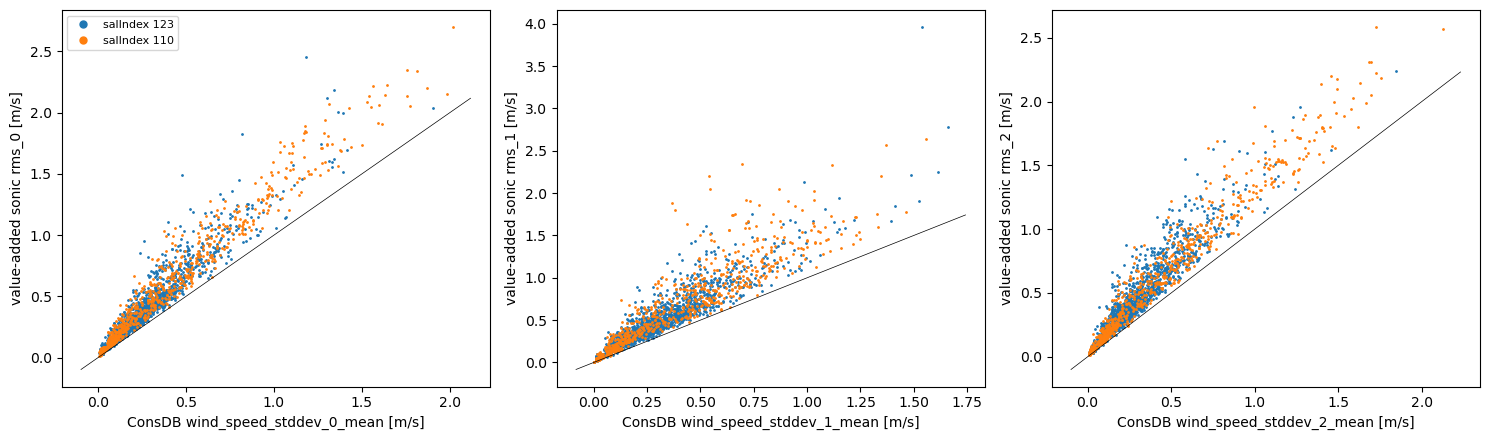

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for a, ax in enumerate(axs):
    for i in (123, 110):
        x = pd.to_numeric(both[f'mt_salindex{i}_wind_speed_stddev_{a}_mean'],
                          errors='coerce')
        y = both[f'sonic{i}_rms_{a}_ms']
        ax.plot(x, y, '.', ms=2, label=f'salIndex {i}')
    lim = ax.get_xlim()
    ax.plot(lim, lim, 'k-', lw=0.5)
    ax.set_xlabel(f'ConsDB wind_speed_stddev_{a}_mean [m/s]')
    ax.set_ylabel(f'value-added sonic rms_{a} [m/s]')
axs[0].legend(markerscale=5, fontsize=8)
fig.tight_layout()
pdf.savefig(fig)
plt.show()

<a id='summary'></a>
## Summary

In [13]:
lines = [
    'PSF shape frame and sonic anemometer check',
    '',
    f'Whiskers: ConsDB per-CCD moments rotated by psf_shape.azel_rotation match the '
    f'RubinTV psf_shape_azel plots for {DAY_OBS} seq {SEQ_NUMS}.',
    f'WCS test: max |WCS Jacobian - azel_rotation| = '
    f'{wcs_tab["max |WCS - azel_rotation|"].max():.4f} (dimensionless) over 4 visits.',
    'AOS OCS: +x_OCS = +Az, +y_OCS = -El, so e1_ocs = e1_azel and e2_ocs = -e2_azel.',
    '',
    'Sonic means, value-added EFD minus ConsDB, median |difference| [m/s], by salIndex:',
]
for i in sal:
    s = sonic_cmp[sonic_cmp.salIndex == i]
    lines.append(f'  {i}: ' + ', '.join(
        f'axis {r.axis} {r._4:.4f} (n {r._3})' for r in s.itertuples()))
fig = plt.figure(figsize=(11, 6))
fig.text(0.05, 0.95, '\n'.join(lines), va='top', family='monospace', fontsize=9)
pdf.savefig(fig)
pdf.close()
print('\n'.join(lines))
print(PDF_PATH)

PSF shape frame and sonic anemometer check

Whiskers: ConsDB per-CCD moments rotated by psf_shape.azel_rotation match the RubinTV psf_shape_azel plots for 20261027 seq [109, 111, 119, 131].
WCS test: max |WCS Jacobian - azel_rotation| = 0.0038 (dimensionless) over 4 visits.
AOS OCS: +x_OCS = +Az, +y_OCS = -El, so e1_ocs = e1_azel and e2_ocs = -e2_azel.

Sonic means, value-added EFD minus ConsDB, median |difference| [m/s], by salIndex:
  110: axis 0 0.0000 (n 723), axis 1 0.0000 (n 723), axis 2 0.0000 (n 723)
  123: axis 0 0.0000 (n 1502), axis 1 0.0000 (n 1502), axis 2 0.0000 (n 1502)
  124: axis 0 0.0000 (n 1502), axis 1 0.0000 (n 1502), axis 2 0.0000 (n 1502)
  125: axis 0 0.0000 (n 1502), axis 1 0.0000 (n 1502), axis 2 0.0000 (n 1502)
  126: axis 0 0.0000 (n 1502), axis 1 0.0000 (n 1502), axis 2 0.0000 (n 1502)
/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/value_added/psf_shape_frame/20261104_azel_vs_rubintv/psf_shape_frame.pdf


<Figure size 1100x600 with 0 Axes>